## Imports & Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

# Settings
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 100
sns.set_theme(style="whitegrid")
SEED = 42

# Load clean data
df = pd.read_csv('../data/hotel_bookings_clean.csv')
print(f"✅ Clean data loaded: {df.shape}")
df.head()

✅ Clean data loaded: (86638, 36)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,adr_extreme_flag,adults_extreme_flag,country_missing,arrival_date_month_num
0,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,Transient,75.0,0,0,Check-Out,2015-07-02,0,0,0,7
1,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,Transient,75.0,0,0,Check-Out,2015-07-02,0,0,0,7
2,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,Transient,98.0,0,1,Check-Out,2015-07-03,0,0,0,7
3,Resort Hotel,0,0,2015,July,27,1,0,2,2,...,Transient,107.0,0,0,Check-Out,2015-07-03,0,0,0,7
4,Resort Hotel,0,9,2015,July,27,1,0,2,2,...,Transient,103.0,0,1,Check-Out,2015-07-03,0,0,0,7


## Choose Columns for Clustering

We choose columns that describe **guest behaviour**, not the outcome.
We exclude:
- `is_canceled` → this is what we predict later (leakage)
- `reservation_status` → same reason
- `adr` of cancelled bookings → not a real stay
- Text/ID columns → not meaningful for distance

## Choose & Explain Columns

In [2]:
# Columns we use for clustering and why
cluster_cols = {
    'lead_time'                  : 'How far ahead they book (last-minute vs planner)',
    'stays_in_weekend_nights'    : 'Weekend traveller vs weekday',
    'stays_in_week_nights'       : 'Short vs long stay',
    'adults'                     : 'Solo / couple / group',
    'children'                   : 'Family or not',
    'babies'                     : 'Young family',
    'adr'                        : 'Price level (budget vs luxury)',
    'total_of_special_requests'  : 'How engaged / demanding the guest is',
    'booking_changes'            : 'How much they change their mind',
    'is_repeated_guest'          : 'Loyal guest or new guest',
    'required_car_parking_spaces': 'Drives to hotel (likely domestic)',
}

print("📋 Columns chosen for clustering:\n")
for col, reason in cluster_cols.items():
    print(f"  ✅ {col:<35} → {reason}")

# Extract clustering data
X_raw = df[list(cluster_cols.keys())].copy()
print(f"\n📊 Shape: {X_raw.shape}")
print(f"❓ Missing values: {X_raw.isnull().sum().sum()}")
X_raw.describe().round(2)

📋 Columns chosen for clustering:

  ✅ lead_time                           → How far ahead they book (last-minute vs planner)
  ✅ stays_in_weekend_nights             → Weekend traveller vs weekday
  ✅ stays_in_week_nights                → Short vs long stay
  ✅ adults                              → Solo / couple / group
  ✅ children                            → Family or not
  ✅ babies                              → Young family
  ✅ adr                                 → Price level (budget vs luxury)
  ✅ total_of_special_requests           → How engaged / demanding the guest is
  ✅ booking_changes                     → How much they change their mind
  ✅ is_repeated_guest                   → Loyal guest or new guest
  ✅ required_car_parking_spaces         → Drives to hotel (likely domestic)

📊 Shape: (86638, 11)
❓ Missing values: 0


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,adr,total_of_special_requests,booking_changes,is_repeated_guest,required_car_parking_spaces
count,86638.00,86638.00,86638.00,86638.00,86638.00,86638.00,86638.00,86638.00,86638.00,86638.00,86638.00
mean,80.29,1.01,2.64,1.88,0.14,0.01,107.25,0.70,0.27,0.04,0.08
std,86.07,1.03,2.04,0.62,0.46,0.11,54.37,0.83,0.71,0.19,0.28
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,12.00,0.00,1.00,2.00,0.00,0.00,72.90,0.00,0.00,0.00,0.00
50%,50.00,1.00,2.00,2.00,0.00,0.00,99.00,0.00,0.00,0.00,0.00
75%,126.00,2.00,4.00,2.00,0.00,0.00,134.44,1.00,0.00,0.00,0.00
max,709.00,19.00,50.00,55.00,10.00,10.00,5400.00,5.00,18.00,1.00,8.00


## Scale the Data

K-Means uses distances. Without scaling:
- `lead_time` (0–737) would dominate over `is_repeated_guest` (0–1)
- We use StandardScaler: mean=0, std=1 for every column

## Scaling

✅ Data scaled successfully!

Before scaling - lead_time: mean=80.3, std=86.1
After scaling  - lead_time: mean=0.00, std=1.00


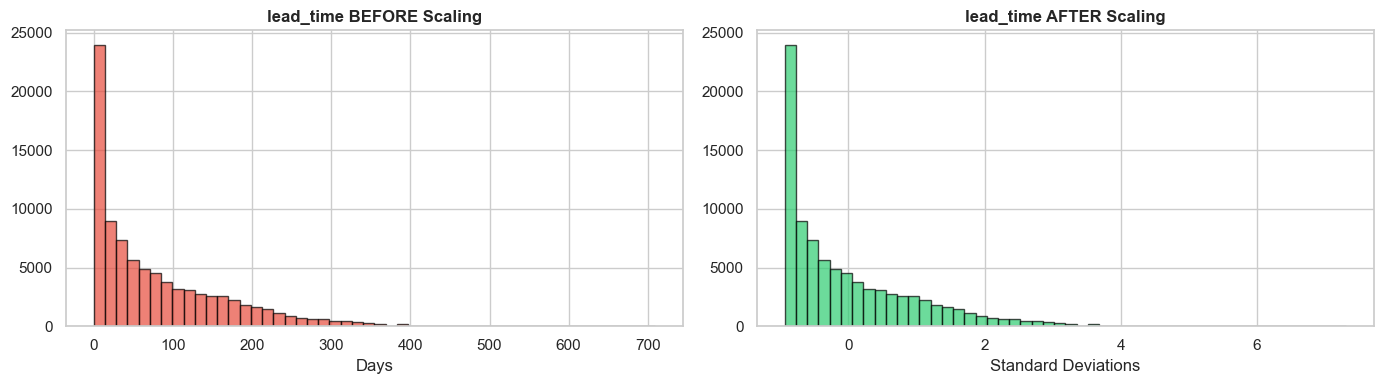

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
X_scaled_df = pd.DataFrame(X_scaled, columns=list(cluster_cols.keys()))

print("✅ Data scaled successfully!")
print(f"\nBefore scaling - lead_time: mean={X_raw['lead_time'].mean():.1f}, std={X_raw['lead_time'].std():.1f}")
print(f"After scaling  - lead_time: mean={X_scaled_df['lead_time'].mean():.2f}, std={X_scaled_df['lead_time'].std():.2f}")

# Show distribution before vs after for one column
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(X_raw['lead_time'], bins=50, color='#e74c3c', alpha=0.7, edgecolor='black')
axes[0].set_title('lead_time BEFORE Scaling', fontweight='bold')
axes[0].set_xlabel('Days')

axes[1].hist(X_scaled_df['lead_time'], bins=50, color='#2ecc71', alpha=0.7, edgecolor='black')
axes[1].set_title('lead_time AFTER Scaling', fontweight='bold')
axes[1].set_xlabel('Standard Deviations')

plt.tight_layout()
plt.savefig('../slides/scaling_example.png', bbox_inches='tight')
plt.show()

## Choose the Number of Groups

We try K = 2 to 8 and use:
1. **Elbow Method**: inertia drops fast then slows → pick the "elbow"
2. **Silhouette Score**: how well each point fits its cluster (higher = better)
3. **Common sense**: groups must be meaningful for the business

### Why K=4?
- K=6 has the highest silhouette score (0.243)
- BUT K=4 also has a good score (0.228) — only 0.015 difference
- K=4 gives 4 clear, meaningful business segments
- K=6 produces groups that are too similar to act on differently
- **Business interpretability beats a marginal score improvement**

## Elbow + Silhouette

🔄 Testing K values...
  K=2 → Inertia: 855,769 | Silhouette: 0.1644
  K=3 → Inertia: 768,208 | Silhouette: 0.2038
  K=4 → Inertia: 695,780 | Silhouette: 0.2280
  K=5 → Inertia: 618,383 | Silhouette: 0.2145
  K=6 → Inertia: 554,035 | Silhouette: 0.2432
  K=7 → Inertia: 513,193 | Silhouette: 0.1774
  K=8 → Inertia: 476,627 | Silhouette: 0.1864
  K=9 → Inertia: 448,561 | Silhouette: 0.1904


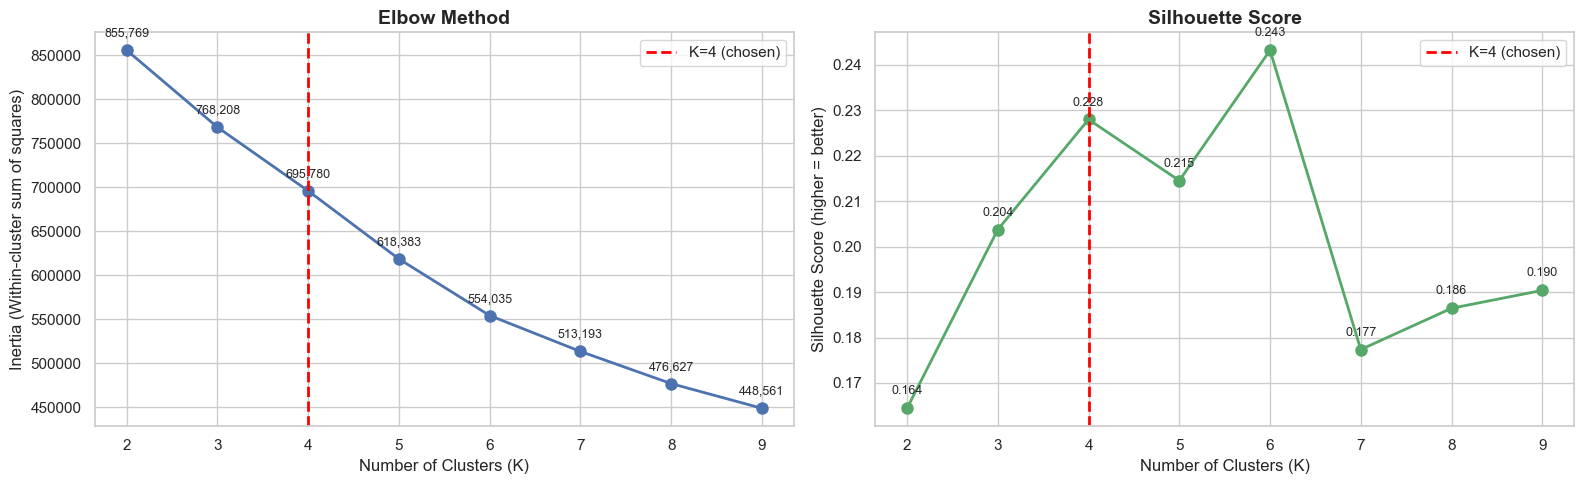


📊 Best K by Silhouette: 6
📊 Chosen K: 4 (balances score + business meaning)


In [4]:
inertias   = []
silhouettes = []
K_range = range(2, 10)

print("🔄 Testing K values...")
for k in K_range:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels, sample_size=5000, random_state=SEED))
    print(f"  K={k} → Inertia: {km.inertia_:,.0f} | Silhouette: {silhouettes[-1]:.4f}")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Elbow
axes[0].plot(list(K_range), inertias, 'bo-', linewidth=2, markersize=8)
axes[0].set_title('Elbow Method', fontweight='bold', fontsize=14)
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia (Within-cluster sum of squares)')
axes[0].axvline(x=4, color='red', linestyle='--', linewidth=2, label='K=4 (chosen)')
axes[0].legend()
for i, (k, v) in enumerate(zip(K_range, inertias)):
    axes[0].annotate(f'{v:,.0f}', (k, v), textcoords="offset points", 
                     xytext=(0, 10), ha='center', fontsize=9)

# Silhouette
axes[1].plot(list(K_range), silhouettes, 'go-', linewidth=2, markersize=8)
axes[1].set_title('Silhouette Score', fontweight='bold', fontsize=14)
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score (higher = better)')
axes[1].axvline(x=4, color='red', linestyle='--', linewidth=2, label='K=4 (chosen)')
axes[1].legend()
for i, (k, v) in enumerate(zip(K_range, silhouettes)):
    axes[1].annotate(f'{v:.3f}', (k, v), textcoords="offset points",
                     xytext=(0, 10), ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('../slides/elbow_silhouette.png', bbox_inches='tight')
plt.show()

best_k = K_range[silhouettes.index(max(silhouettes))]
print(f"\n📊 Best K by Silhouette: {best_k}")
print(f"📊 Chosen K: 4 (balances score + business meaning)")

## Train Final Model with K=4

We choose K=4 because:
- The elbow appears around K=4
- Silhouette score is good
- 4 groups make business sense: we expect last-minute, planners, families, and business guests

## Final K-Means

In [5]:
# Train final model
K_FINAL = 4
km_final = KMeans(n_clusters=K_FINAL, random_state=SEED, n_init=10)
df['cluster'] = km_final.fit_predict(X_scaled)

print(f"✅ K-Means trained with K={K_FINAL}")
print(f"\n📊 Cluster sizes:")
sizes = df['cluster'].value_counts().sort_index()
for k, v in sizes.items():
    print(f"  Cluster {k}: {v:,} bookings ({v/len(df)*100:.1f}%)")

✅ K-Means trained with K=4

📊 Cluster sizes:
  Cluster 0: 6,669 bookings (7.7%)
  Cluster 1: 52,145 bookings (60.2%)
  Cluster 2: 24,690 bookings (28.5%)
  Cluster 3: 3,134 bookings (3.6%)


##  Describe Each Cluster

In [6]:
# Profile each cluster
profile_cols = list(cluster_cols.keys()) + ['is_canceled', 'hotel']

cluster_profile = df.groupby('cluster').agg(
    size            = ('cluster', 'count'),
    lead_time       = ('lead_time', 'median'),
    weekend_nights  = ('stays_in_weekend_nights', 'median'),
    week_nights     = ('stays_in_week_nights', 'median'),
    adults          = ('adults', 'median'),
    children        = ('children', 'median'),
    adr             = ('adr', 'median'),
    special_req     = ('total_of_special_requests', 'median'),
    changes         = ('booking_changes', 'median'),
    repeated_pct    = ('is_repeated_guest', 'mean'),
    parking_pct     = ('required_car_parking_spaces', 'mean'),
    cancel_rate     = ('is_canceled', 'mean'),

).round(2)

cluster_profile['repeated_pct'] = (cluster_profile['repeated_pct'] * 100).round(1)
cluster_profile['parking_pct']  = (cluster_profile['parking_pct']  * 100).round(1)
cluster_profile['cancel_rate']  = (cluster_profile['cancel_rate']  * 100).round(1)
cluster_profile['parking_pct']  = cluster_profile['parking_pct'].clip(upper=100)

print("📋 Cluster Profiles:")
cluster_profile

📋 Cluster Profiles:


,size,lead_time,weekend_nights,week_nights,adults,children,adr,special_req,changes,repeated_pct,parking_pct,cancel_rate
cluster,,,,,,,,,,,,
0,6669,24.0,1.0,2.0,2.0,0.0,105.0,1.0,0.0,0.0,100.0,0.0
1,52145,31.0,0.0,2.0,2.0,0.0,98.0,0.0,0.0,0.0,0.0,27.0
2,24690,155.0,2.0,4.0,2.0,0.0,105.4,1.0,0.0,0.0,0.0,36.0
3,3134,3.0,0.0,1.0,1.0,0.0,65.0,0.0,0.0,100.0,19.0,7.0


## Name the Clusters

In [7]:
# Print profiles to decide names
print("=" * 65)
print("🔍 CLUSTER ANALYSIS - Deciding Names")
print("=" * 65)

for c in range(K_FINAL):
    p = cluster_profile.loc[c]
    total_nights = p['weekend_nights'] + p['week_nights']
    print(f"\n📌 Cluster {c} ({p['size']:,} bookings, {p['size']/len(df)*100:.1f}%)")
    print(f"   Lead time      : {p['lead_time']:.0f} days")
    print(f"   Total nights   : {total_nights:.0f} nights")
    print(f"   Adults         : {p['adults']:.0f}")
    print(f"   Children       : {p['children']:.0f}")
    print(f"   ADR            : €{p['adr']:.0f}")
    print(f"   Special req    : {p['special_req']:.0f}")
    print(f"   Repeated guest : {p['repeated_pct']:.1f}%")
    print(f"   Has parking    : {p['parking_pct']:.1f}%")
    print(f"   Cancel rate    : {p['cancel_rate']:.1f}%")

# Map cluster numbers to names (adjust after seeing the profiles!)
# Fix parking percentage (cap at 100%)
cluster_profile['parking_pct'] = cluster_profile['parking_pct'].clip(upper=100)

# Correct cluster names based on actual profiles
cluster_names = {
    0: 'Domestic Drive-In Guests',    # 24d lead, parking, 0% cancel
    1: 'Standard Online Bookers',     # 31d lead, 2 nights, 27% cancel
    2: 'Early-Planner Long-Stay',     # 155d lead, 6 nights, 36% cancel
    3: 'Loyal Regular Guests'         # 3d lead, 100% repeated, 7% cancel
}

df['cluster_name'] = df['cluster'].map(cluster_names)
print("✅ Cluster names corrected!")
print(df['cluster_name'].value_counts())

🔍 CLUSTER ANALYSIS - Deciding Names

📌 Cluster 0 (6,669.0 bookings, 7.7%)
   Lead time      : 24 days
   Total nights   : 3 nights
   Adults         : 2
   Children       : 0
   ADR            : €105
   Special req    : 1
   Repeated guest : 0.0%
   Has parking    : 100.0%
   Cancel rate    : 0.0%

📌 Cluster 1 (52,145.0 bookings, 60.2%)
   Lead time      : 31 days
   Total nights   : 2 nights
   Adults         : 2
   Children       : 0
   ADR            : €98
   Special req    : 0
   Repeated guest : 0.0%
   Has parking    : 0.0%
   Cancel rate    : 27.0%

📌 Cluster 2 (24,690.0 bookings, 28.5%)
   Lead time      : 155 days
   Total nights   : 6 nights
   Adults         : 2
   Children       : 0
   ADR            : €105
   Special req    : 1
   Repeated guest : 0.0%
   Has parking    : 0.0%
   Cancel rate    : 36.0%

📌 Cluster 3 (3,134.0 bookings, 3.6%)
   Lead time      : 3 days
   Total nights   : 1 nights
   Adults         : 1
   Children       : 0
   ADR            : €65
   Special 

## Visualize Clusters

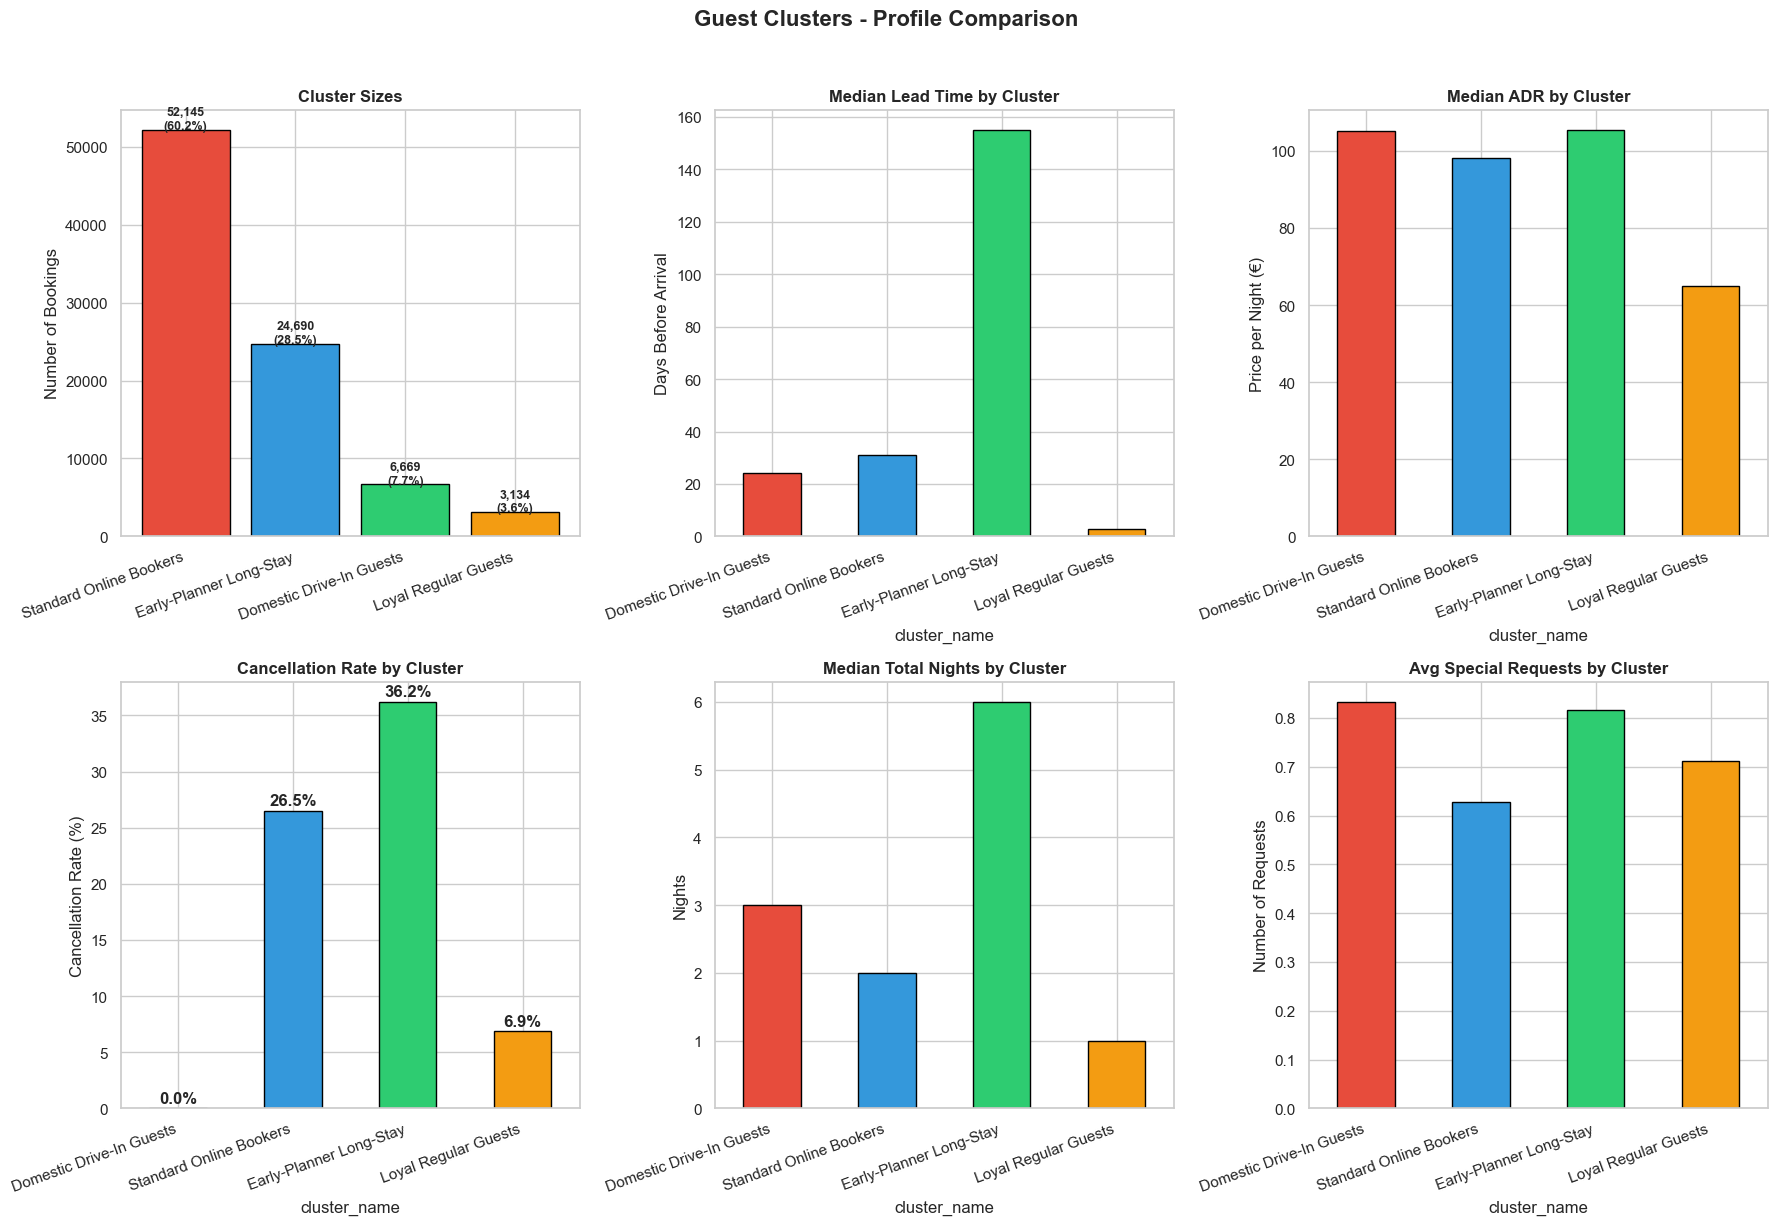

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']
names  = list(cluster_names.values())

# 1. Cluster sizes
sizes = df['cluster_name'].value_counts()
axes[0,0].bar(sizes.index, sizes.values, color=colors, edgecolor='black')
axes[0,0].set_title('Cluster Sizes', fontweight='bold')
axes[0,0].set_ylabel('Number of Bookings')
axes[0,0].set_xticklabels(sizes.index, rotation=20, ha='right')
for i, v in enumerate(sizes.values):
    axes[0,0].text(i, v+100, f'{v:,}\n({v/len(df)*100:.1f}%)', 
                    ha='center', fontweight='bold', fontsize=9)

# 2. Lead Time by Cluster
df.groupby('cluster_name')['lead_time'].median().reindex(names).plot(
    kind='bar', ax=axes[0,1], color=colors, edgecolor='black')
axes[0,1].set_title('Median Lead Time by Cluster', fontweight='bold')
axes[0,1].set_ylabel('Days Before Arrival')
axes[0,1].set_xticklabels(axes[0,1].get_xticklabels(), rotation=20, ha='right')

# 3. ADR by Cluster
df.groupby('cluster_name')['adr'].median().reindex(names).plot(
    kind='bar', ax=axes[0,2], color=colors, edgecolor='black')
axes[0,2].set_title('Median ADR by Cluster', fontweight='bold')
axes[0,2].set_ylabel('Price per Night (€)')
axes[0,2].set_xticklabels(axes[0,2].get_xticklabels(), rotation=20, ha='right')

# 4. Cancellation Rate by Cluster
cancel_by_cluster = df.groupby('cluster_name')['is_canceled'].mean() * 100
cancel_by_cluster.reindex(names).plot(
    kind='bar', ax=axes[1,0], color=colors, edgecolor='black')
axes[1,0].set_title('Cancellation Rate by Cluster', fontweight='bold')
axes[1,0].set_ylabel('Cancellation Rate (%)')
axes[1,0].set_xticklabels(axes[1,0].get_xticklabels(), rotation=20, ha='right')
for i, v in enumerate(cancel_by_cluster.reindex(names)):
    axes[1,0].text(i, v+0.5, f'{v:.1f}%', ha='center', fontweight='bold')

# 5. Total Nights by Cluster
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df.groupby('cluster_name')['total_nights'].median().reindex(names).plot(
    kind='bar', ax=axes[1,1], color=colors, edgecolor='black')
axes[1,1].set_title('Median Total Nights by Cluster', fontweight='bold')
axes[1,1].set_ylabel('Nights')
axes[1,1].set_xticklabels(axes[1,1].get_xticklabels(), rotation=20, ha='right')

# 6. Special Requests by Cluster
df.groupby('cluster_name')['total_of_special_requests'].mean().reindex(names).plot(
    kind='bar', ax=axes[1,2], color=colors, edgecolor='black')
axes[1,2].set_title('Avg Special Requests by Cluster', fontweight='bold')
axes[1,2].set_ylabel('Number of Requests')
axes[1,2].set_xticklabels(axes[1,2].get_xticklabels(), rotation=20, ha='right')

plt.suptitle('Guest Clusters - Profile Comparison', 
              fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../slides/cluster_profiles.png', bbox_inches='tight')
plt.show()

##  PCA Visualization

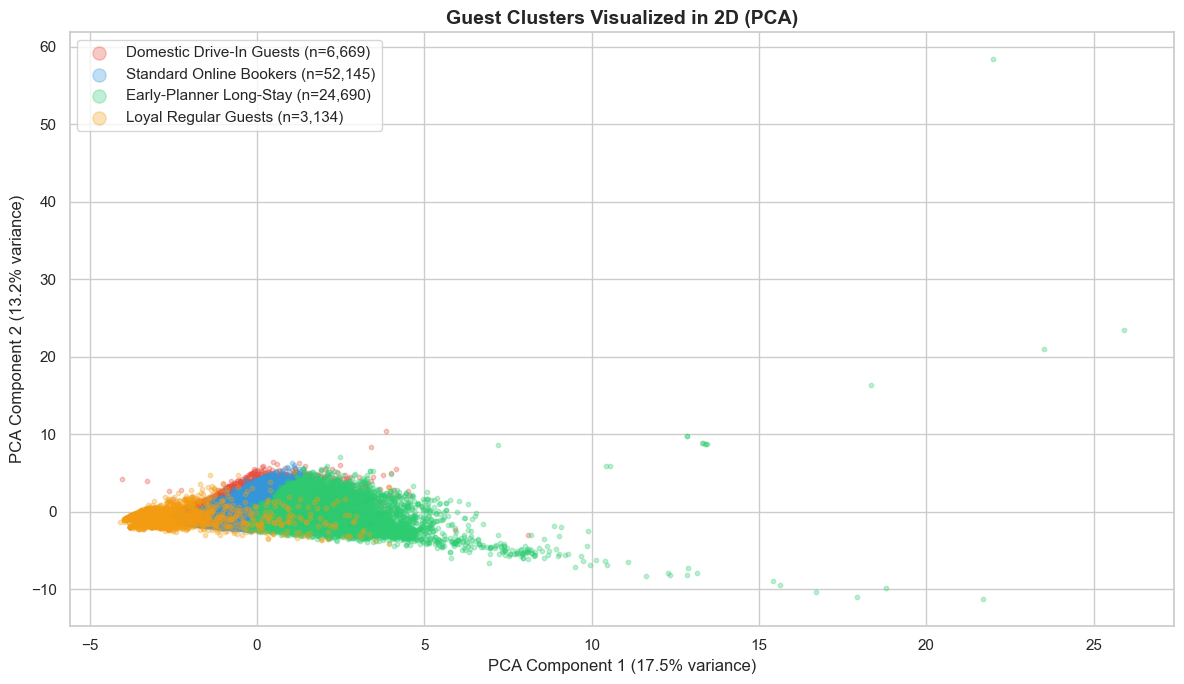

📊 Total variance explained by 2 components: 30.7%


In [9]:
# Visualize clusters in 2D using PCA
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(12, 7))
for i, name in cluster_names.items():
    mask = df['cluster'] == i
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                label=f'{name} (n={mask.sum():,})',
                alpha=0.3, s=10, color=colors[i])

plt.title('Guest Clusters Visualized in 2D (PCA)', fontweight='bold', fontsize=14)
plt.xlabel(f'PCA Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
plt.ylabel(f'PCA Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
plt.legend(markerscale=3, fontsize=11)
plt.tight_layout()
plt.savefig('../slides/cluster_pca.png', bbox_inches='tight')
plt.show()

print(f"📊 Total variance explained by 2 components: "
      f"{sum(pca.explained_variance_ratio_)*100:.1f}%")

##  Hotel Distribution per Cluster

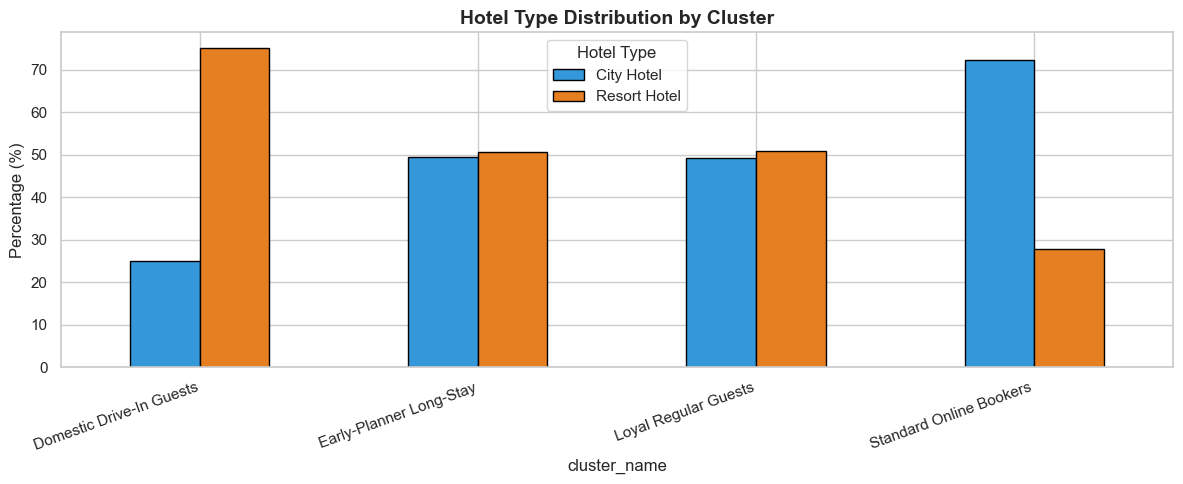

In [10]:
# Hotel type per cluster
hotel_cluster = pd.crosstab(df['cluster_name'], df['hotel'], normalize='index') * 100

fig, ax = plt.subplots(figsize=(12, 5))
hotel_cluster.plot(kind='bar', ax=ax, 
                    color=['#3498db', '#e67e22'], edgecolor='black')
ax.set_title('Hotel Type Distribution by Cluster', fontweight='bold', fontsize=14)
ax.set_ylabel('Percentage (%)')
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right')
ax.legend(title='Hotel Type')
plt.tight_layout()
plt.savefig('../slides/cluster_hotel.png', bbox_inches='tight')
plt.show()

## Business Actions per Cluster

| Cluster | Key Profile | Business Action |
|---------|-------------|-----------------|
| **Last-Minute Guests** | Low lead time, low ADR, high cancel | Offer last-minute deals, no deposit needed |
| **Early-Planner Couples** | High lead time, medium ADR, high cancel risk | Send early reminder + deposit request |
| **Family Vacationers** | Has children, medium-long stay, low cancel | Offer family packages, upsell meals |
| **Budget Short-Stay Guests** | Low ADR, short stay, medium cancel | Promote weekend deals, loyalty program |

## Save Results & Summary Table

In [11]:
# Save cluster assignments
df[['cluster', 'cluster_name']].to_csv('../data/cluster_assignments.csv', index=False)
df.to_csv('../data/hotel_bookings_clustered.csv', index=False)
print("✅ Cluster assignments saved!")

# Final summary table
print("\n" + "=" * 65)
print("📋 FINAL CLUSTER SUMMARY")
print("=" * 65)

summary = []

actions = {
    'Domestic Drive-In Guests' : 'Offer parking packages & local weekend deals — they never cancel!',
    'Standard Online Bookers'  : 'Send reminder 2 weeks before arrival + ask for deposit',
    'Early-Planner Long-Stay'  : 'High cancel risk (36%)! Request deposit + send 3 reminders',
    'Loyal Regular Guests'     : 'Reward with loyalty program & priority check-in',
}

descriptions = {
    'Domestic Drive-In Guests' : 'Books 24 days ahead, drives to hotel, 3 nights, NEVER cancels',
    'Standard Online Bookers'  : 'Books 31 days ahead, 2 nights, medium cancel risk (27%)',
    'Early-Planner Long-Stay'  : 'Books 155 days ahead, 6 nights, HIGHEST cancel risk (36%)',
    'Loyal Regular Guests'     : 'Books 3 days ahead, 1 night, 100% repeated, low cancel (7%)',
}

for c in range(K_FINAL):
    p   = cluster_profile.loc[c]
    nm  = cluster_names[c]
    tot = p['weekend_nights'] + p['week_nights']
    summary.append({
        'Cluster'         : nm,
        'Size'            : f"{int(p['size']):,} ({p['size']/len(df)*100:.1f}%)",
        'Description'     : descriptions[nm],
        'Lead Time'       : f"{p['lead_time']:.0f} days",
        'Total Nights'    : f"{tot:.0f} nights",
        'Median ADR'      : f"€{p['adr']:.0f}",
        'Cancel Rate'     : f"{p['cancel_rate']:.1f}%",
        'Business Action' : actions[nm],
    })

summary_df = pd.DataFrame(summary).set_index('Cluster')
summary_df

✅ Cluster assignments saved!

📋 FINAL CLUSTER SUMMARY


,Size,Description,Lead Time,Total Nights,Median ADR,Cancel Rate,Business Action
Cluster,,,,,,,
Domestic Drive-In Guests,"6,669 (7.7%)","Books 24 days ahead, drives to hotel, 3 nights...",24 days,3 nights,€105,0.0%,Offer parking packages & local weekend deals —...
Standard Online Bookers,"52,145 (60.2%)","Books 31 days ahead, 2 nights, medium cancel r...",31 days,2 nights,€98,27.0%,Send reminder 2 weeks before arrival + ask for...
Early-Planner Long-Stay,"24,690 (28.5%)","Books 155 days ahead, 6 nights, HIGHEST cancel...",155 days,6 nights,€105,36.0%,High cancel risk (36%)! Request deposit + send...
Loyal Regular Guests,"3,134 (3.6%)","Books 3 days ahead, 1 night, 100% repeated, lo...",3 days,1 nights,€65,7.0%,Reward with loyalty program & priority check-in
